# This is a non LLM workflow

In [1]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

#graph ->> START----->CAL_BMI----->END


In [2]:
#define state
class BMIState(TypedDict):
    weight_kg: float
    height_m: float
    bmi: float

In [3]:
#calculate BMI
def calculate_bmi(state: BMIState) -> BMIState:
    weight = state['weight_kg']
    height = state['height_m']
    bmi = weight / (height ** 2)
    state['bmi'] = round(bmi, 2) #round up to 2 decimal places
    return state

In [4]:
#define your graph
graph = StateGraph(BMIState)

#add nodes to your graphs
graph.add_node("calculate_bmi", calculate_bmi) # nodes are python functions that take in a state and return a state

#add edges to your graph
graph.add_edge(START, "calculate_bmi")
graph.add_edge("calculate_bmi", END)

#compile your graph
workflow = graph.compile()

In [5]:
#execute your graph
workflow.invoke({"weight_kg": 70, "height_m": 1.75})

{'weight_kg': 70, 'height_m': 1.75, 'bmi': 22.86}

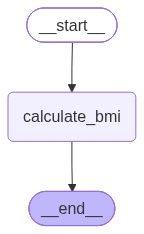

In [6]:
#lets check the visualization of the graph
from IPython.display import Image, display

# Assuming 'graph' is your compiled StateGraph
display(Image(workflow.get_graph().draw_mermaid_png()))


#this code only works in jupyter notebook, if you want to run it in a python script, you can use the following code to visualize the graph
#workflow.get_graph().draw_mermaid("bmi_workflow.mmd") # this will create a file called bmi_workflow.mmd in the current directory, you can then use mermaid-cli to convert it to png or svg

In [7]:
# lets make it more advance 
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

#graph ->> START----->CAL_BMI----->category----->END

In [8]:
class BMIState(TypedDict):
    weight_kg: float
    height_m: float
    bmi: float
    category: str

In [9]:
# make a function
def calculate_bmi(state: BMIState) -> BMIState:
    weight = state['weight_kg']
    height = state['height_m']
    bmi = weight / (height ** 2)
    state['bmi'] = round(bmi, 2) #round up to 2 decimal places
    return state


In [10]:
def categorize_bmi(state: BMIState) -> BMIState:
    bmi = state['bmi']
    if bmi < 18.5:
        state['category'] = 'Underweight'
    elif 18.5 <= bmi < 24.9:
        state['category'] = 'Normal weight'
    elif 25 <= bmi < 29.9:
        state['category'] = 'Overweight'
    else:
        state['category'] = 'Obesity'
    return state

In [11]:
graph = StateGraph(BMIState)
# add nodes to your graphs
graph.add_node("calculate_bmi", calculate_bmi) # nodes are python functions that take in a state and return a state
graph.add_node("categorize_bmi", categorize_bmi) # nodes are python functions that take in a state and return a state

#add edges to your graph
graph.add_edge(START, "calculate_bmi")
graph.add_edge("calculate_bmi", "categorize_bmi")
graph.add_edge("categorize_bmi", END)

#compile your graph
workflow = graph.compile()

In [12]:
result=workflow.invoke({"weight_kg": 80, "height_m": 1.73})
print(result)  # Output: {'weight_kg': 70, 'height_m': 1.75, 'bmi': 22.86, 'category': 'Normal weight'}

{'weight_kg': 80, 'height_m': 1.73, 'bmi': 26.73, 'category': 'Overweight'}


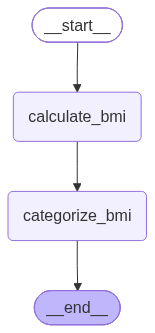

In [13]:
from IPython.display import Image, display
# Assuming 'graph' is your compiled StateGraph
display(Image(workflow.get_graph().draw_mermaid_png()))